# 06 - Translation: choose the best model and produce the translated file

**Pipeline so far:** photo → text lines → recognised text (TCN + beam + character LM) → language (Hindi / Marathi).
**This notebook adds:** recognised text → **translation**, then writes one file with
*image · language · recognised text · translations · how reliable the recognition was*.

## 1. Translation model used in this Windows setup

This notebook uses **NLLB-200 distilled 600M** as the working local translation baseline.

| model | size | status |
|---|---:|---|
| **NLLB-200 distilled** | 600M | **Enabled** — works locally with PyTorch + Transformers 4.49.0; no Hugging Face login required |
| **IndicTrans2-200M** | 200M | Optional research comparison only — requires gated Hugging Face access and `IndicTransToolkit`; it is not required for this Windows run |
| **IndicTrans2-1B** | 1B | Optional research comparison only; not used in the current CPU setup |

**Current decision:** run the reproducible NLLB baseline first. IndicTrans2 is not allowed to stop the notebook. If you later install the Microsoft C++ Build Tools and obtain gated Hugging Face access, it can be added as a separate comparison.

## 2. How the models are compared (read this — it matters for the report)

The dataset has **no human translations**, so BLEU against a reference is not available out of the box. Two measurements are used instead:

* **Retention** = chrF++ between the translation of the *recognised* text and the translation of the *true* transcript, by the same model.
  It answers: *how much of the correct translation survives the handwriting-recognition errors?*
* A **copy check** rejects outputs that remain largely in Devanagari.

If you (or someone bilingual) write English translations for ~20 pages, the notebook can also score against those human references using chrF++ and BLEU.

**Retention measures robustness, not absolute correctness.** Say that clearly in the report, and prefer the human-reference score when you have it.

### Current environment

Use the VS Code/Jupyter kernel:

**Python 3.11 (Translation Env)**

Required packages: `transformers==4.49.0`, `torch`, `sentencepiece`, `sacrebleu`, `openpyxl`, `pandas`, `scipy`, `matplotlib`, `tqdm`, `huggingface_hub`.

**NLLB does not require `IndicTransToolkit` or a Hugging Face login.**

In [1]:
import os, sys, json, time, pickle
sys.path.insert(0, ".")
from pathlib import Path

# Environment check: this notebook is intended for Python 3.11 (Translation Env).
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from tqdm.auto import tqdm
import torch
import transformers

print("Python:", sys.version)
print("Python path:", sys.executable)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA:", torch.cuda.is_available())

if sys.version_info[:2] != (3, 11):
    raise RuntimeError("Wrong Python kernel. Select: Python 3.11 (Translation Env)")
if transformers.__version__ != "4.49.0":
    raise RuntimeError(f"Wrong Transformers version: {transformers.__version__}. Install transformers==4.49.0")

import htr_data as D
import htr_translate as TR

OUT = Path("htr_outputs"); RES = OUT / "results"; FIG = OUT / "figures"; TRD = OUT / "translation"
for p in (FIG, TRD): p.mkdir(parents=True, exist_ok=True)

SEED = 42
# NLLB is the only automatically enabled model in this Windows/CPU run.
CANDIDATES = ["nllb_600M"]
FORCE_MODEL = "nllb_600M"
TARGETS = ["English", "Telugu", "Hindi", "Marathi"]
N_EVAL_PAGES = 40
BEAMS = 4
INCLUDE_UNLABELLED = True

if os.environ.get("HTR_MOCK"):
    CANDIDATES, TARGETS, N_EVAL_PAGES = ["mock"], ["English", "Telugu", "Hindi", "Marathi"], 12

print("candidates:", CANDIDATES, "| targets:", TARGETS)

c:\Users\dasar\Downloads\Final Year Capstone Project\translation_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Python path: c:\Users\dasar\Downloads\Final Year Capstone Project\translation_env\Scripts\python.exe
PyTorch: 2.14.1+cpu
Transformers: 4.49.0
CUDA: False
candidates: ['nllb_600M'] | targets: ['English', 'Telugu', 'Hindi', 'Marathi']


In [2]:
# NLLB smoke test: fail early before starting the 40-page evaluation.
if not os.environ.get("HTR_MOCK"):
    print("Loading NLLB-200 distilled 600M...")
    backend = TR.make_backend("nllb_600M", beams=BEAMS)
    print("✓ NLLB backend loaded successfully")


Loading NLLB-200 distilled 600M...
✓ NLLB backend loaded successfully


## 3. Load the recognised text, language and a reliability flag

Badly read pages (see the first test page: CER 0.75, output mostly stray vowel signs) would be translated into confident-looking nonsense.
So every page gets a **reference-free reliability tier** from two signals: how *unlikely* the text is under the character LM trained on your
training transcripts, and how many words are impossible Devanagari. Section 3's table checks that the tiers really track the true CER.

In [4]:
man = pd.read_csv(OUT / "manifest.csv", encoding="utf-8-sig")
lm = D.CharNgramLM(order=5).fit(list(man[man.split == "train"].text))
baseline = float(np.mean([TR.bits_per_char(t, lm) for t in man[man.split == "val"].text]))
print(f"bits/char of CLEAN validation transcripts under the LM (the baseline): {baseline:.3f}")

try:
    with open(OUT / "models" / "lid.pkl", "rb") as f:
        lid = pickle.load(f)
except Exception as e:
    print("could not load lid.pkl (", type(e).__name__, ") -> using the true language instead"); lid = None

def add_language_and_reliability(df, text_col):
    df = df.copy(); df[text_col] = df[text_col].fillna("").astype(str)
    if lid is not None:
        proba, classes = lid.predict_proba(list(df[text_col]))
        df["pred_language"] = [classes[i] for i in proba.argmax(1)]; df["confidence"] = proba.max(1)
    rel = pd.DataFrame([TR.reliability(t, lm, baseline) for t in df[text_col]], index=df.index)
    return pd.concat([df, rel], axis=1)

test = pd.read_csv(RES / "test_final_predictions.csv", encoding="utf-8-sig")
test = add_language_and_reliability(test, "prediction")
if "pred_language" not in test:
    test["pred_language"], test["confidence"] = test.language, 1.0
print("\nDoes the reliability tier track the real recognition error? (test pages)")
display(test.groupby("reliability").agg(pages=("id", "count"), mean_CER=("CER", "mean"), median_CER=("CER", "median")).round(3)
        .reindex(["HIGH", "MEDIUM", "LOW"]))
print("Spearman(bits/char, CER) =", round(spearmanr(test.bits_per_char, test.CER)[0], 3))

bits/char of CLEAN validation transcripts under the LM (the baseline): 4.132
could not load lid.pkl ( ModuleNotFoundError ) -> using the true language instead

Does the reliability tier track the real recognition error? (test pages)


,pages,mean_CER,median_CER
reliability,,,
HIGH,36,0.147,0.118
MEDIUM,34,0.199,0.183
LOW,20,0.309,0.264


Spearman(bits/char, CER) = 0.615


## 4. Compare the translation models on your pages

Each model translates, for every evaluation page, (a) the **true transcript** and (b) the **recognised text** into English.
Translations are cached on disk, so you can stop and resume. **On a CPU this is the slow part** (roughly 10–40 minutes per model for 40 pages); lower `N_EVAL_PAGES` for a first run.

In [5]:
eval_pages = pd.concat([g.sample(min(len(g), N_EVAL_PAGES // 2), random_state=SEED)
                        for _, g in test.groupby("language")]).reset_index(drop=True)
print("evaluation pages:", len(eval_pages), eval_pages.language.value_counts().to_dict())

translators, rows = {}, []
for name in CANDIDATES:
    try:
        tr = TR.ParagraphTranslator(TR.make_backend(name, beams=BEAMS), TRD / f"cache_{name}.jsonl")
        part = []
        for r in tqdm(list(eval_pages.itertuples()), desc=name):
            clean = tr(r.reference, r.language, "English")
            noisy = tr(r.prediction, r.pred_language, "English")
            part.append(dict(model=name, id=r.id, language=r.language, CER=r.CER, reliability=r.reliability,
                             clean_en=clean, noisy_en=noisy, retention=TR.chrf(noisy, clean),
                             devanagari_share=TR.script_share(noisy)))
    except Exception as e:
        print(f"\n!! {name} failed: {type(e).__name__}: {str(e)[:500]}")
        if name == "nllb_600M":
            print("   Check Python 3.11 (Translation Env), PyTorch, and Transformers 4.49.0.")
        elif name.startswith("it2_"):
            print("   IndicTrans2 is optional and is not required for this NLLB baseline.")
        continue
    translators[name] = tr
    rows += part

if not translators:
    raise RuntimeError("NLLB could not be run. Check the environment/kernel and the NLLB smoke-test cell above.")

CANDIDATES = list(translators)
cmp = pd.DataFrame(rows)
cmp.to_csv(TRD / "model_comparison_pages.csv", index=False, encoding="utf-8-sig")

def boot_ci(x, n=2000, seed=0):
    rng = np.random.default_rng(seed); x = np.asarray(x)
    m = [rng.choice(x, len(x)).mean() for _ in range(n)]
    return np.percentile(m, [2.5, 97.5])

summary = cmp.groupby("model").agg(pages=("id", "count"), retention_chrF=("retention", "mean"),
                                   devanagari_in_output=("devanagari_share", "mean"))
summary["ci_low"] = [boot_ci(cmp[cmp.model == m].retention)[0] for m in summary.index]
summary["ci_high"] = [boot_ci(cmp[cmp.model == m].retention)[1] for m in summary.index]
display(summary.round(3))

if len(CANDIDATES) > 1:
    a, b = CANDIDATES[0], CANDIDATES[1]
    ca = cmp[cmp.model == a].set_index("id").clean_en; cb = cmp[cmp.model == b].set_index("id").clean_en
    print(f"agreement between {a} and {b} on the CLEAN text (chrF++): {np.mean([TR.chrf(ca[i], cb[i]) for i in ca.index]):.1f}")


evaluation pages: 40 {'Hindi': 20, 'Marathi': 20}


nllb_600M: 100%|██████████| 40/40 [1:49:22<00:00, 164.07s/it]  


,pages,retention_chrF,devanagari_in_output,ci_low,ci_high
model,,,,,
nllb_600M,40,38.643,0.0,33.977,43.314


### Optional: score against human translations (the proper measure)

A template with 20 pages is written to `htr_outputs/translation/reference_translations.csv`. Have someone bilingual type the English
translation of the *true* Hindi/Marathi text in the `english` column, save, and re-run this cell. When it exists, it decides the model choice.

In [6]:
REF_FILE = TRD / "reference_translations.csv"
human = None
if not REF_FILE.exists():
    tmpl = eval_pages[["id", "language", "reference"]].head(20).rename(columns={"reference": "source_text"}); tmpl["english"] = ""
    tmpl.to_csv(REF_FILE, index=False, encoding="utf-8-sig")
    print("template written ->", REF_FILE, "(fill the 'english' column to unlock human-reference scoring)")
else:
    ref = pd.read_csv(REF_FILE, encoding="utf-8-sig").fillna(""); ref = ref[ref.english.str.strip() != ""]
    if len(ref):
        hr = cmp.merge(ref[["id", "english"]], on="id")
        hr["chrF_clean"] = [TR.chrf(h, r) for h, r in zip(hr.clean_en, hr.english)]
        hr["chrF_noisy"] = [TR.chrf(h, r) for h, r in zip(hr.noisy_en, hr.english)]
        hr["BLEU_noisy"] = [TR.bleu(h, r) for h, r in zip(hr.noisy_en, hr.english)]
        human = hr.groupby("model")[["chrF_clean", "chrF_noisy", "BLEU_noisy"]].mean()
        print(f"{hr.id.nunique()} human-translated pages")
        display(human.round(2))
    else:
        print("template exists but 'english' is empty")

template written -> htr_outputs\translation\reference_translations.csv (fill the 'english' column to unlock human-reference scoring)


## 5. Choose the model

In [7]:
eligible = summary[summary.devanagari_in_output < 0.10]          # reject models that mostly copy the input
if eligible.empty:
    print("WARNING: every model left much Devanagari in its English output - check the translations before trusting this choice")
    eligible = summary
if human is not None:
    score, basis = human.chrF_noisy.reindex(eligible.index), "chrF++ against human references, on recognised text"
else:
    score, basis = eligible.retention_chrF, "retention (robustness to recognition errors)"
BEST = FORCE_MODEL or score.idxmax()
print("basis for the choice:", basis); print(score.round(2).to_string()); print("\n=> BEST MODEL:", BEST)

basis for the choice: retention (robustness to recognition errors)
model
nllb_600M    38.64

=> BEST MODEL: nllb_600M


## 6. Error propagation: recognition errors → translation errors

For the chosen model: how much of the correct English translation is lost as the handwriting-recognition error (CER) of a page grows?

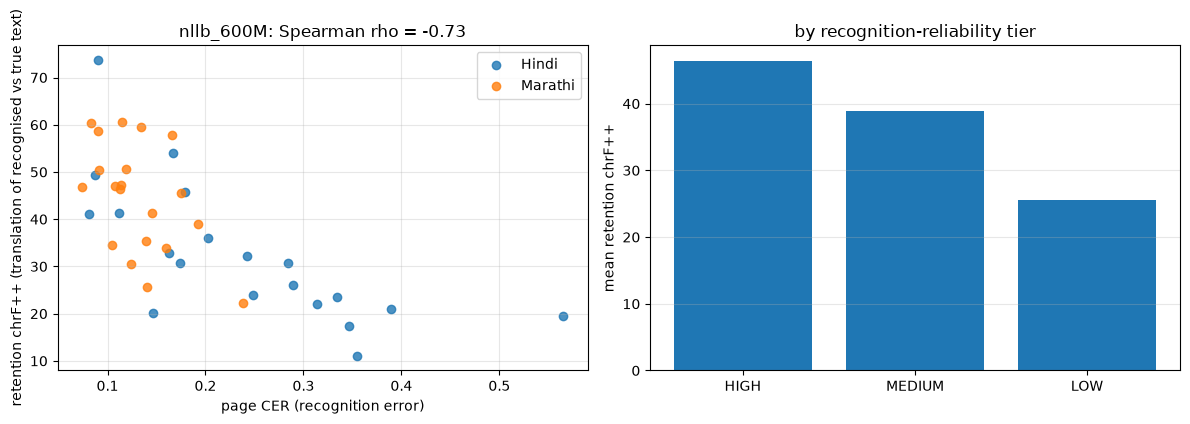

,pages,mean_CER,retention
reliability,,,
HIGH,18,0.13,46.42
MEDIUM,11,0.18,38.95
LOW,11,0.28,25.60


In [8]:
b = cmp[cmp.model == BEST]
rho = spearmanr(b.CER, b.retention)[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for lang, g in b.groupby("language"):
    ax[0].scatter(g.CER, g.retention, label=lang, alpha=.8)
ax[0].set_xlabel("page CER (recognition error)"); ax[0].set_ylabel("retention chrF++ (translation of recognised vs true text)")
ax[0].set_title(f"{BEST}: Spearman rho = {rho:.2f}"); ax[0].legend(); ax[0].grid(alpha=.3)
order = ["HIGH", "MEDIUM", "LOW"]
means = b.groupby("reliability").retention.mean().reindex(order)
ax[1].bar(order, means.fillna(0)); ax[1].set_ylabel("mean retention chrF++"); ax[1].set_title("by recognition-reliability tier"); ax[1].grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "translation_error_propagation.png", dpi=150); plt.show()
display(b.groupby("reliability").agg(pages=("id", "count"), mean_CER=("CER", "mean"), retention=("retention", "mean")).round(2).reindex(order))

## 7. Produce the translated file

Uses the chosen model on all test pages (and the end-to-end pages from notebook 05). Same-language targets are skipped.
Output: `htr_outputs/results/translations.csv` and `translations.xlsx` (colour-coded by reliability).

In [ ]:
tr = translators.get(BEST) or TR.ParagraphTranslator(TR.make_backend(BEST, beams=BEAMS), TRD / f"cache_{BEST}.jsonl")

pages = test.rename(columns={"id": "image", "prediction": "recognised_text", "reference": "true_text"}).copy()
pages["source"] = "test (labelled)"; pages["true_language"] = pages.language
pages = pages[["image", "source", "true_language", "pred_language", "confidence", "reliability", "recognised_text", "true_text", "CER"]]
if INCLUDE_UNLABELLED and (RES / "unlabelled_test_predictions.csv").exists():
    unl = pd.read_csv(RES / "unlabelled_test_predictions.csv", encoding="utf-8-sig").rename(columns={"recognised": "recognised_text"})
    unl = add_language_and_reliability(unl.assign(recognised_text=unl.recognised_text.fillna("")), "recognised_text")
    unl = unl.drop(columns=[c for c in ("pred_language_y", "confidence_y") if c in unl], errors="ignore")
    unl["source"] = "end-to-end (unlabelled folders)"
    pages = pd.concat([pages, unl[[c for c in pages.columns if c in unl]]], ignore_index=True)

t0 = time.time()
for tgt in TARGETS:
    col = f"translation_{tgt}"
    vals = []
    for r in tqdm(list(pages.itertuples()), desc=f"-> {tgt}"):
        if not str(r.recognised_text).strip():
            vals.append("")
        elif TR.to_code(r.pred_language) == TR.to_code(tgt):
            vals.append("(same language)")
        else:
            vals.append(tr(r.recognised_text, r.pred_language, tgt))
    pages[col] = vals
print(f"done in {(time.time() - t0) / 60:.1f} min")

pages.to_csv(RES / "translations.csv", index=False, encoding="utf-8-sig")
display(pages[["image", "pred_language", "reliability", "recognised_text"] + [f"translation_{t}" for t in TARGETS[:2]]].head(5))

-> English:   6%|▌         | 10/170 [10:26<3:51:41, 86.89s/it]

In [ ]:
from openpyxl.styles import Alignment, PatternFill, Font
xlsx = RES / "translations.xlsx"
info = pd.DataFrame({"item": ["translation model", "selection basis", "recognition model", "recognition decoder", "reliability tiers",
                              "important"],
                     "value": [BEST, basis, "TCN", "beam search + character LM", "HIGH / MEDIUM / LOW from LM bits-per-char and invalid-word rate (heuristic)",
                               "Translations of LOW-reliability pages are probably wrong because the recognised text is wrong."]})
with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
    pages.to_excel(xw, index=False, sheet_name="translations"); info.to_excel(xw, index=False, sheet_name="about")
    ws = xw.sheets["translations"]; ws.freeze_panes = "A2"
    colour = {"HIGH": "C6EFCE", "MEDIUM": "FFEB9C", "LOW": "FFC7CE"}
    for j, name in enumerate(pages.columns, start=1):
        width = 60 if name in ("recognised_text", "true_text") or name.startswith("translation_") else 16
        ws.column_dimensions[ws.cell(1, j).column_letter].width = width
        ws.cell(1, j).font = Font(bold=True)
        for i in range(2, len(pages) + 2):
            ws.cell(i, j).alignment = Alignment(wrap_text=True, vertical="top")
    rel_col = list(pages.columns).index("reliability") + 1
    for i in range(2, len(pages) + 2):
        ws.cell(i, rel_col).fill = PatternFill("solid", fgColor=colour.get(ws.cell(i, rel_col).value, "FFFFFF"))
    xw.sheets["about"].column_dimensions["A"].width = 24; xw.sheets["about"].column_dimensions["B"].width = 110
print("saved:", RES / "translations.csv", "and", xlsx)

json.dump({"candidates": CANDIDATES, "best_model": BEST, "selection_basis": basis, "targets": TARGETS,
           "eval_pages": int(len(eval_pages)), "summary": summary.round(4).reset_index().to_dict("records"),
           "error_propagation_spearman": float(rho), "pages_translated": int(len(pages)),
           "reliability_counts": pages.reliability.value_counts().to_dict()},
          open(RES / "translation_summary.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)

## 8. What to write in the report

* **Method:** page → lines → CTC recogniser (TCN, beam + character LM) → language ID → NLLB-200 distilled 600M translation.
* **Translation baseline:** NLLB-200 distilled 600M was selected because it runs locally in the Python 3.11 CPU environment without gated-model access or IndicTransToolkit.
* **Finding:** section 6 shows how recognition errors propagate into translation quality, and whether the reliability tier can warn about pages whose translation should not be trusted.
* **Limits:** only Hindi/Marathi sources; ~300 training pages; translations of poorly read pages are unreliable; retention is not human-judged translation accuracy.
* **Human-reference evaluation:** if bilingual English references are entered, report chrF++/BLEU against those references and prefer those results over retention for claims about translation quality.

For a **single new photo**: `python translate.py photo.jpg --to English,Telugu` (writes a `_translation.txt` next to it).